# Systemy AI – Laboratorium 1
## Python, NumPy i pierwsze metryki klasyfikacji

**Cel:** przypomnienie Pythona w kontekście pracy z wynikami modeli, samodzielna implementacja metryk klasyfikacji binarnej i pierwszy mały eksperyment z hipotezą.

**Zasady**
- Zapisz kopię notatnika na swoim Dysku: *Plik → Zapisz kopię na Dysku*, nazwa `Lab1_AI_Nazwisko.ipynb`.
- Rozwiązania wpisuj w komórkach `# Twoje rozwiązanie`, odpowiedzi opisowe w komórkach *Twoja odpowiedź*.
- Komórki oznaczone `# TEST` sprawdzają rozwiązanie. Nie zmieniaj ich; jeśli zgłaszają błąd, popraw kod powyżej.
- Przed oddaniem: *Środowisko wykonawcze → Uruchom ponownie i uruchom wszystko*. Notatnik musi wykonać się od góry do dołu bez błędów.



**Materiały pomocnicze**
- Python: https://www.w3schools.com/python/ oraz https://www.kaggle.com/learn/python
- NumPy: https://numpy.org/doc/stable/user/quickstart.html
- Metryki w scikit-learn: https://scikit-learn.org/stable/modules/model_evaluation.html

---
## Część A. Rozgrzewka

### Zadanie A1. Pierwsze komórki
1. Wypisz instrukcją `print` tekst `Hello, Artificial Intelligence!`.

In [ ]:
print("Hello, Artificial Inteligence!")

Hello, Artificial Inteligence!


*Twoja odpowiedź:*

### Zadanie A2. Zmienne i typy
Zadeklaruj zmienne `model`, `version`, `accuracy`, `deployed` o wartościach `"NeuralNet"`, `2`, `0.94`, `True`.

1. Wypisz typ każdej zmiennej (`type()`).
2. Zbuduj i wypisz zdanie `Model NeuralNet (v2) osiąga dokładność 0.94.` na dwa sposoby: przez konkatenację (`+`, zmienna `s1`) oraz jako f-string (zmienna `s2`).


In [ ]:
model = "NeuralNet"
version = 2
accuracy = 0.94
deployed = True

print(type(model))
print(type(version))
print(type(accuracy))
print(type(deployed))

s1 = "Model " + model + " (v" + str(version) + ") osiąga dokładność " + str(accuracy) + "."
s2 = f"Model {model} (v{version}) osiąga dokładność {accuracy}."

<class 'str'>
<class 'int'>
<class 'float'>
<class 'bool'>


In [ ]:
# TEST
assert s1 == s2 == "Model NeuralNet (v2) osiąga dokładność 0.94."
print("A2 OK")

A2 OK


### Zadanie A3. Średnia i odchylenie standardowe
Dla listy `acc = [0.78, 0.86, 0.92, 0.81]` oblicz **bez bibliotek**:
- średnią `mean_acc`,
- odchylenie standardowe populacji `std_acc` (z dzieleniem przez $n$):

$$\sigma = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(x_i-\bar{x})^2}$$

W komórce tekstowej zinterpretuj wynik: co mówi odchylenie o tych czterech modelach? Jak zmieni się wartość, jeśli podzielisz przez $n-1$, i kiedy stosuje się ten wariant?

In [ ]:
acc = [0.78, 0.86, 0.92, 0.81]
mean_acc = sum(acc) / len(acc)
std_acc = (sum((x - mean_acc) ** 2 for x in acc) / len(acc)) ** 0.5

print (mean_acc)
print (std_acc)

0.8425
0.05309190145398825


In [ ]:
# TEST
assert abs(mean_acc - 0.8425) < 1e-9
assert abs(std_acc - 0.05309) < 1e-4, "Sprawdź, czy dzielisz przez n, a nie n-1"
print("A3 OK")

A3 OK


*Twoja odpowiedź:*

### Zadanie A4. Tekst i słownik częstości
Dla tekstu

`text = "AI systems learn from data. AI systems make predictions from data"`

1. Usuń interpunkcję, zamień litery na małe i podziel tekst na słowa.
2. Zbuduj słownik `counts` w postaci `{słowo: liczba_wystąpień}`.
3. Zapisz w liście `most_common` **wszystkie** słowa o największej liczbie wystąpień (uwaga na remisy) i wypisz ją.

In [ ]:
text = "AI systems learn from data. AI systems make predictions from data"
text = text.replace(".", "").lower().split()
counts = {}
for word in text:
    if word in counts:
        counts[word] += 1
    else:
        counts[word] = 1
most_common = [word for word, count in counts.items() if count == max(counts.values())]
print(counts)
print(most_common)

{'ai': 2, 'systems': 2, 'learn': 1, 'from': 2, 'data': 2, 'make': 1, 'predictions': 1}
['ai', 'systems', 'from', 'data']


In [ ]:
# TEST
assert counts["data"] == 2 and counts["learn"] == 1
assert sorted(most_common) == ["ai", "data", "from", "systems"]
print("A4 OK")

A4 OK


### Zadanie A5. Funkcja z walidacją
Napisz funkcję `performance_label(score)`, która zamienia wynik modelu `score` ∈ [0, 1] na etykietę:

| Warunek | Etykieta |
|---|---|
| `score < 0.75` | `"weak"` |
| `0.75 ≤ score ≤ 0.90` | `"average"` |
| `score > 0.90` | `"strong"` |

Wymagania:
- progi 0.75 i 0.90 należą do `"average"`; funkcja nie zaokrągla wejścia,
- dla wartości nieliczbowej (np. `"0.8"`, `None`) funkcja zgłasza `TypeError`,
- dla liczby spoza [0, 1] funkcja zgłasza `ValueError`.

Następnie dla listy `scores = [0.72, 0.81, 0.93, 0.88]` wypisz każdy wynik z etykietą i policz średnią `mean_ok` tylko z wyników, które **nie** są `"weak"`.

In [ ]:
def performance_label(score):
    if not isinstance(score, (int, float)):
        raise TypeError
    if score < 0 or score > 1:
        raise ValueError
    if score < 0.75:
        return "weak"
    elif score <= 0.90:
        return "average"
    else:
        return "strong"

scores = [0.72, 0.81, 0.93, 0.88]
mean_ok_len = len([score for score in scores if performance_label(score) != "weak"])
mean_ok = sum(score for score in scores if performance_label(score) != "weak") / mean_ok_len
print(mean_ok)

0.8733333333333334


In [ ]:
# TEST
assert [performance_label(s) for s in (0.74, 0.75, 0.90, 0.95)] == ["weak", "average", "average", "strong"]
assert performance_label(0) == "weak" and performance_label(1) == "strong"

for bad, exc in [(1.2, ValueError), (-0.1, ValueError), ("0.8", TypeError), (None, TypeError)]:
    try:
        performance_label(bad)
    except exc:
        pass
    else:
        raise AssertionError(f"Dla {bad!r} oczekiwano wyjątku {exc.__name__}")

assert abs(mean_ok - 0.87333) < 1e-4
print("A5 OK")

A5 OK


---
## Część B. Struktury danych i wyniki modeli

### Zadanie B1. Słownik wyników i ranking
1. Utwórz słownik `results`: `"SVM"` → 0.81, `"DecisionTree"` → 0.74, `"NeuralNet"` → 0.92.
2. Dodaj do niego `"Transformer"` → 0.95.
3. Oblicz średnią dokładność `mean_results` i utwórz listę `above_mean` z nazwami modeli o dokładności powyżej średniej.
4. Napisz funkcję `print_ranking(results)`, która drukuje ranking malejąco w formacie

```
1. Transformer – 0.95
2. NeuralNet – 0.92
...
Najlepszy model: Transformer – rekomendowany do wdrożenia
```

i **zwraca** nazwę najlepszego modelu. Funkcja nie może modyfikować przekazanego słownika.

In [ ]:
results = {"SVM": 0.81, "DecisionTree":0.74, "NeuralNet":0.92}
results["Transformer"] = 0.95
mean_results = sum(results.values()) / len(results)
above_mean = [model for model, score in results.items() if score > mean_results]

def print_ranking(results):
    sorted_results = sorted(results.items(), key=lambda x: x[1], reverse=True)
    for i, (model, score) in enumerate(sorted_results, start=1):
        print(f"{i}. {model} – {score}")
    print(f"Najlepszy model: {sorted_results[0][0]} – rekomendowany do wdrożenia")
    return sorted_results[0][0]

print_ranking(results)

1. Transformer – 0.95
2. NeuralNet – 0.92
3. SVM – 0.81
4. DecisionTree – 0.74
Najlepszy model: Transformer – rekomendowany do wdrożenia


'Transformer'

In [ ]:
# TEST
assert abs(mean_results - 0.855) < 1e-9
assert sorted(above_mean) == ["NeuralNet", "Transformer"]
assert print_ranking({"A": 0.5, "B": 0.7}) == "B"
assert list(results) == ["SVM", "DecisionTree", "NeuralNet", "Transformer"], "Funkcja zmieniła słownik"
print("B1 OK")

1. B – 0.7
2. A – 0.5
Najlepszy model: B – rekomendowany do wdrożenia
B1 OK


### Zadanie B2. Filtrowanie błędnych wyników
Dane z eksperymentów bywają zanieczyszczone. Dla listy

`raw = [0.83, 0.92, 1.05, -0.12, 0.78, None]`

napisz funkcję `clean_scores(raw)`, która zwraca parę `(valid, n_invalid)`:
- `valid` – lista poprawnych wyników (liczby z zakresu [0, 1]),
- `n_invalid` – liczba odrzuconych wartości.

Wypisz komunikat dokładnie w formacie:

`Poprawne: 3 | Błędne: 3 | Średnia (poprawnych): 0.84`

*Dla dociekliwych:* co Twoja funkcja zrobi z wartościami `"0.9"` i `True`? Czy tak powinno być?

In [ ]:
raw = [0.83, 0.92, 1.05, -0.12, 0.78, None]

def clean_scores(raw):
    valid = [score for score in raw if isinstance(score, (int, float)) and 0 <= score <= 1]
    n_invalid = len(raw) - len(valid)
    return valid, n_invalid

valid, n_invalid = clean_scores(raw)
mean_valid = sum(valid) / len(valid)

print(f"Poprawne: {len(valid)} | Błędne: {n_invalid} | Średnia (poprawnych): {mean_valid}" )

Poprawne: 3 | Błędne: 3 | Średnia (poprawnych): 0.8433333333333334


In [ ]:
# TEST
assert clean_scores([0.83, 0.92, 1.05, -0.12, 0.78, None]) == ([0.83, 0.92, 0.78], 3)
assert clean_scores([0, 1, "0.9"]) == ([0, 1], 1)
print("B2 OK")

B2 OK


### Zadanie B3. Struktura zagnieżdżona
Dla struktury `model_info` (komórka niżej) napisz funkcję `summarize_model(info)`, która:
1. wypisuje nazwę modelu,
2. oblicza i wypisuje średnią ze **wszystkich** metryk w `info["metrics"]` (nie zakładaj, że są dokładnie trzy),
3. wypisuje `Model gotowy do wdrożenia`, jeśli średnia ≥ 0.9, w przeciwnym razie `Model wymaga poprawy`,
4. zapisuje średnią pod kluczem `info["mean_score"]` i zwraca cały słownik.

Wywołaj funkcję: `model_info = summarize_model(model_info)`.

In [ ]:
model_info = {
    "name": "NeuralNet",
    "version": "1.2",
    "metrics": {"accuracy": 0.91, "precision": 0.88, "recall": 0.85},
    "status": "trained",
}

In [ ]:
def summarize_model(info):
  print (info["name"])
  mean_score = sum(info["metrics"].values()) / len(info["metrics"])
  print (mean_score)
  if mean_score >= 0.9:
    print ("Model gotowy do wdrożenia")
  else:
    print ("Model wymaga poprawy")
  info["mean_score"] = mean_score
  return info

model_info = summarize_model(model_info)

NeuralNet
0.88
Model wymaga poprawy


In [ ]:
# TEST
assert abs(model_info["mean_score"] - 0.88) < 1e-9
assert abs(summarize_model({"name": "X", "metrics": {"accuracy": 0.95, "f1": 0.93}})["mean_score"] - 0.94) < 1e-9
print("B3 OK")

X
0.94
Model gotowy do wdrożenia
B3 OK


---
## Część C. Metryki klasyfikacji binarnej

Przypomnienie (klasa pozytywna = 1):

| | predykcja 1 | predykcja 0 |
|---|---|---|
| **prawda 1** | TP | FN |
| **prawda 0** | FP | TN |

$$\text{accuracy}=\frac{TP+TN}{TP+TN+FP+FN}\qquad \text{precision}=\frac{TP}{TP+FP}\qquad \text{recall}=\frac{TP}{TP+FN}\qquad F_1=\frac{2\cdot\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}}$$

In [9]:
y_true = [1, 0, 1, 1, 0, 0, 1, 0, 1, 0]
y_pred = [1, 0, 1, 0, 0, 1, 1, 0, 0, 0]

### Zadanie C1. Ręcznie, w czystym Pythonie
Używając pętli (bez bibliotek) policz i zapisz w zmiennych `TP`, `FP`, `FN`, `TN`, a następnie `precision`, `recall` i `f1`. Wypisz raport:

`TP=.. FP=.. FN=.. TN=.. / precision=.. recall=.. F1=..`

In [4]:
TP = 0
FP = 0
FN = 0
TN = 0

for i in range(len(y_true)):
  if y_true[i] == 1 and y_pred[i] == 1:
    TP += 1
  if y_true[i] == 0 and y_pred[i] == 1:
    FP += 1
  if y_true[i] == 1 and y_pred[i] == 0:
    FN += 1
  if y_true[i] == 0 and y_pred[i] == 0:
    TN += 1

precision = TP/(TP+FP)
recall = TP/(TP+FN)
f1 = (2*precision*recall)/(precision+recall)

print(f"TP = {TP}  FP= {FP}  FN={FN}  TN= {TN}  / precision = {precision}  recal= {recall} F1= {f1}")

TP = 3  FP= 1  FN=2  TN= 4  / precision = 0.75  recal= 0.6 F1= 0.6666666666666665


In [5]:
# TEST
assert (TP, FP, FN, TN) == (3, 1, 2, 4)
assert abs(precision - 0.75) < 1e-9 and abs(recall - 0.6) < 1e-9 and abs(f1 - 2 / 3) < 1e-9
print("C1 OK")

C1 OK


### Zadanie C2. To samo w NumPy
Napisz funkcję `binary_metrics(y_true, y_pred)`, która **bez pętli** (maski logiczne i `sum`) zwraca słownik z kluczami

`"TP", "FP", "FN", "TN", "accuracy", "precision", "recall", "f1"`.

Jeśli mianownik którejś metryki jest równy 0 (np. model ani razu nie przewidział klasy 1), przyjmij dla niej wartość `0.0`. Funkcja ma działać zarówno dla list, jak i tablic NumPy.

In [18]:
import numpy as np

def binary_metrics(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    TP = int(np.sum((y_true == 1) & (y_pred == 1)))
    FP = int(np.sum((y_true == 0) & (y_pred == 1)))
    FN = int(np.sum((y_true == 1) & (y_pred == 0)))
    TN = int(np.sum((y_true == 0) & (y_pred == 0)))
    mian_acc = TP + TN + FP + FN
    accuracy = (TP + TN) / (mian_acc) if mian_acc>0 else 0.0
    mian_prec = TP + FP
    precision = TP/(mian_prec) if mian_prec>0 else 0.0
    mian_recall = TP + FN
    recall = TP/(TP+FN) if mian_recall>0 else 0.0
    mian_f1 = precision+recall
    f1 = (2*precision*recall)/(mian_f1) if mian_f1>0 else 0.0
    return {"TP": TP, "FP": FP, "FN": FN, "TN": TN, "accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}

m = binary_metrics(y_true, y_pred)
print(m)





{'TP': 3, 'FP': 1, 'FN': 2, 'TN': 4, 'accuracy': 0.7, 'precision': 0.75, 'recall': 0.6, 'f1': 0.6666666666666665}


In [19]:
# TEST
m = binary_metrics(y_true, y_pred)
assert (m["TP"], m["FP"], m["FN"], m["TN"]) == (3, 1, 2, 4)
assert abs(m["accuracy"] - 0.7) < 1e-9 and abs(m["f1"] - 2 / 3) < 1e-9

m0 = binary_metrics([1, 0, 0, 0], [0, 0, 0, 0])   # model nigdy nie przewiduje 1
assert m0["precision"] == 0.0 and m0["recall"] == 0.0 and m0["f1"] == 0.0
print("C2 OK")

C2 OK


### Zadanie C3. Porównanie ze scikit-learn
Policz te same wielkości funkcjami `confusion_matrix`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score` z modułu `sklearn.metrics` i sprawdź (`np.isclose`), że zgadzają się z wynikiem `binary_metrics`.

W komentarzu zapisz, w jakim układzie `confusion_matrix` zwraca TP, FP, FN, TN. Sprawdź to w dokumentacji, nie zgaduj.

In [22]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

m = binary_metrics(y_true, y_pred)
tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

sk_accuracy = accuracy_score(y_true, y_pred)
sk_precision = precision_score(y_true, y_pred, zero_division=0)
sk_recall = recall_score(y_true, y_pred, zero_division=0)
sk_f1 = f1_score(y_true, y_pred, zero_division=0)

assert np.isclose(m["accuracy"], sk_accuracy)
assert np.isclose(m["precision"], sk_precision)
assert np.isclose(m["recall"], sk_recall)
assert np.isclose(m["f1"], sk_f1)
print("OK")

OK


---
## Część D. Mini-eksperyment: kiedy accuracy wprowadza w błąd

Rozważ dwa „modele” wykrywające rzadkie zjawisko (np. chorobę, awarię, oszustwo):

- **zawsze-zero** – niezależnie od wejścia odpowiada 0,
- **zaszumiony** – zna prawdziwą odpowiedź, ale w 10% przypadków (losowo) podaje przeciwną.

Parametr $p$ to udział klasy pozytywnej w danych.

### Zadanie D1. Hipoteza
**Zanim uruchomisz jakikolwiek kod**, zapisz przewidywania dla $p = 0.05$:
- jaką accuracy osiągnie każdy z modeli?
- który model będzie miał wyższą accuracy?
- jaką precision będzie miał model zaszumiony: bliżej 0.9, 0.5 czy 0.3?

*Twoja odpowiedź:*

accuracy w modelu zawsze - zero będzie bardzo wysoka, natomiast acuracy zaszumionego modelu bedzię sporo niższa.

accuracy w modelu zerowym bedzie wyzsza

precision w modelu zaszumionym według mnie będzie to wynik bliżej 0.9

Funkcja poniżej generuje dane. Jest gotowa, przeczytaj ją i upewnij się, że rozumiesz każdą linię.

In [23]:
import numpy as np

def make_data(p, n=10_000, error_rate=0.10, seed=42):
    """Zwraca (y_true, y_zero, y_noisy) dla udziału klasy pozytywnej p."""
    rng = np.random.default_rng(seed)
    y_true = (rng.random(n) < p).astype(int)        # 1 z prawdopodobieństwem p
    y_zero = np.zeros(n, dtype=int)                 # model zawsze-zero
    flip = rng.random(n) < error_rate               # które odpowiedzi odwrócić
    y_noisy = np.where(flip, 1 - y_true, y_true)    # model zaszumiony
    return y_true, y_zero, y_noisy

### Zadanie D2. Eksperyment
1. Dla $p = 0.05$ policz funkcją `binary_metrics` metryki obu modeli i porównaj z przewidywaniami z D1.
2. Powtórz obliczenia dla `ps = [0.5, 0.3, 0.1, 0.05, 0.01]`. Wyniki zbierz w tabeli `pandas.DataFrame` o nazwie `df` z kolumnami `p`, `model`, `accuracy`, `precision`, `recall`, `f1` (po jednym wierszu na parę: wartość $p$, model).
3. Narysuj wykres (matplotlib): oś X to $p$ w skali logarytmicznej, na osi Y accuracy obu modeli oraz precision modelu zaszumionego. Podpisz osie i dodaj legendę.

In [24]:
y_true_md, y_zero, y_noisy = make_data(p=0.05)

y_zero_res = binary_metrics(y_true_md, y_zero)
y_noisy_res = binary_metrics(y_true_md, y_noisy)

print(y_zero_res)
print(y_noisy_res)

{'TP': 0, 'FP': 0, 'FN': 508, 'TN': 9492, 'accuracy': 0.9492, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0}
{'TP': 470, 'FP': 926, 'FN': 38, 'TN': 8566, 'accuracy': 0.9036, 'precision': 0.336676217765043, 'recall': 0.9251968503937008, 'f1': 0.49369747899159666}



--- Tabela wyników df ---
      p        model  accuracy  precision    recall        f1
0  0.50  zawsze-zero    0.4985   0.000000  0.000000  0.000000
1  0.50        noisy    0.9036   0.902284  0.905882  0.904080
2  0.30  zawsze-zero    0.6957   0.000000  0.000000  0.000000
3  0.30        noisy    0.9036   0.802268  0.906671  0.851280
4  0.10  zawsze-zero    0.9016   0.000000  0.000000  0.000000
5  0.10        noisy    0.9036   0.505663  0.907520  0.649455
6  0.05  zawsze-zero    0.9492   0.000000  0.000000  0.000000
7  0.05        noisy    0.9036   0.336676  0.925197  0.493697
8  0.01  zawsze-zero    0.9899   0.000000  0.000000  0.000000
9  0.01        noisy    0.9036   0.090995  0.950495  0.166090


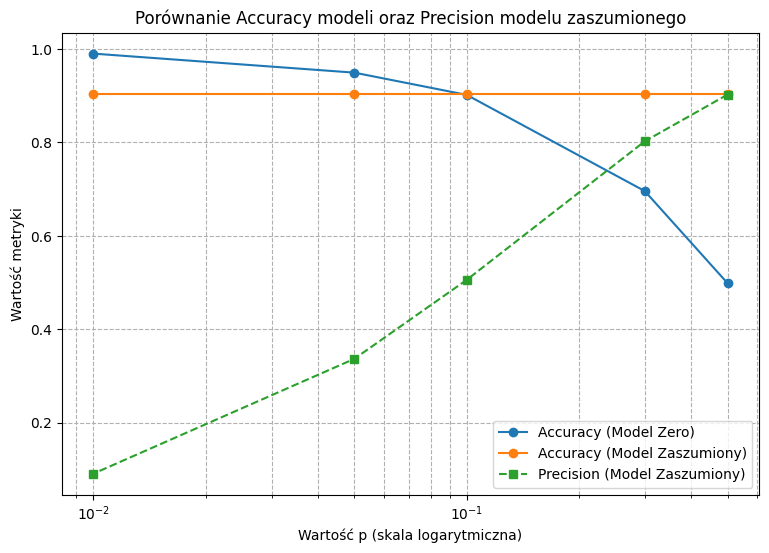

In [32]:
import matplotlib.pyplot as plt
import pandas as pd


ps = [0.5, 0.3, 0.1, 0.05, 0.01]
rows = []

for p in ps:
    yt, yz, yn = make_data(p)
    mz = binary_metrics(yt, yz)
    mn = binary_metrics(yt, yn)

    rows.append({"p": p, "model": "zawsze-zero", **mz})
    rows.append({"p": p, "model": "noisy", **mn})

df = pd.DataFrame(rows)
print("\n--- Tabela wyników df ---")
print(df[['p', 'model', 'accuracy', 'precision', 'recall', 'f1']])


plt.figure(figsize=(9, 6))

df_zero = df[df['model'] == 'zawsze-zero']
df_noisy = df[df['model'] == 'noisy']

plt.plot(df_zero['p'], df_zero['accuracy'], marker='o', label='Accuracy (Model Zero)')
plt.plot(df_noisy['p'], df_noisy['accuracy'], marker='o', label='Accuracy (Model Zaszumiony)')
plt.plot(df_noisy['p'], df_noisy['precision'], marker='s', linestyle='--', label='Precision (Model Zaszumiony)')

plt.xscale('log')
plt.xlabel('Wartość p (skala logarytmiczna)')
plt.ylabel('Wartość metryki')
plt.title('Porównanie Accuracy modeli oraz Precision modelu zaszumionego')
plt.legend()
plt.grid(True, which="both", ls="--")
plt.show()


In [31]:
# TEST
assert set(df.columns) >= {"p", "model", "accuracy", "precision", "recall", "f1"}
assert len(df) == 10
z = df[(df["model"] == "zawsze-zero") & (df["p"] == 0.01)].iloc[0]
assert z["accuracy"] > 0.98 and z["recall"] == 0.0
print("D2 OK")

D2 OK


### Zadanie D3. Wnioski
Odpowiedz krótko (2–3 zdania na pytanie), odwołując się do liczb z tabeli:

1. Czy Twoje przewidywania z D1 się potwierdziły? Co Cię zaskoczyło?
2. Dla $p = 0.01$: który model ma wyższą accuracy, a który jest bardziej użyteczny? Dlaczego?
3. Model zaszumiony myli się zawsze w 10% przypadków. Dlaczego mimo to jego precision spada, gdy $p$ maleje?
4. Projektujesz system wykrywający rzadką chorobę. Którą metrykę zaraportujesz jako główną? Jakie konsekwencje dla pacjentów mają błędy FP, a jakie FN?

*Twoja odpowiedź:*

O dziwo accuracy modelu zaszumionego jest na wysokim stałym poziomie, a accuracy modelu zerowego wraz z p dążącym do 0 jest na wyższym poziomie.

Wyższą accuracy dla p = 0.01 ma model zawsze-zero, mimo tego uważam że wyższą użyteczność ma model zaszumiony ponieważ wykrywa rzadki przypadek występowania pozytywnej klasy

jego precision spada ponieważ przy rzadkich zdarzeniach liczba rzeczywistych pozytywów jest bardzo mała.

Kluczową metryką będzie recall uzupełniony przez precision, ponieważ accuracy jest w tym przypadku całkowicie mylące.

---
## Część E. Zadania dodatkowe (dla chętnych / do domu)

**E1. Pliki.** Zapisz listę wyników (po jednym w linii) do pliku `scores.txt`. Wczytaj plik, oblicz średnią i zapisz do `report.txt` raport w formacie `Wczytano N wyników, średnia: X` (X z dokładnością do 3 miejsc po przecinku).

**E2. Dane od użytkownika.** Pobierz funkcją `input()` wynik modelu `s` i wypisz:
- `Podano niepoprawną wartość!`, gdy tekstu nie da się zamienić na liczbę (`try`/`except`),
- `Wynik poza zakresem 0–1`, gdy `s < 0` lub `s > 1`,
- `Model wymaga poprawy`, gdy `s < 0.7`,
- `Wynik akceptowalny`, gdy `0.7 ≤ s < 0.85`,
- `Wynik doskonały` w pozostałych przypadkach.

**E3. Duplikaty.** Usuń duplikaty z listy `["SVM", "SVM", "NeuralNet", "NeuralNet", "Transformer"]` **z zachowaniem kolejności** pierwszych wystąpień. Dlaczego samo `list(set(...))` tego nie gwarantuje?

**E4. Uogólnienie.** Rozszerz `make_data` o parametr pozwalający ustawić osobno odsetek błędów dla przykładów pozytywnych i negatywnych. Jak zmienia się wykres z D2, gdy model myli się w 10% pozytywnych, ale tylko w 1% negatywnych?

In [ ]:
# Twoje rozwiązanie